# Chapter 11 : Training Deep Neural Networks

**Exercice 1 : Training a deep neural network on the CIFAR10 image dataset**

In [2]:
import copy
import json
import math
import time
from datetime import datetime as dt
from pathlib import Path

import matplotlib.pyplot as plt
import optuna
import torch
import torchmetrics
import torchvision
import torchvision.transforms.v2 as T
from torch import nn
from torch.optim.lr_scheduler import OneCycleLR
from torch.utils.data import DataLoader

/Users/voisin/Code/HOMLwithPytorch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
if torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

a) Load CIFAR10 using torchvision

In [4]:
toTensor = T.Compose([T.ToImage(), T.ToDtype(torch.float32, scale=True)])

train_and_valid_data = torchvision.datasets.CIFAR10(
    root="datasets", train=True, download=True, transform=toTensor
)
test_data = torchvision.datasets.CIFAR10(
    root="datasets", train=False, download=True, transform=toTensor
)

torch.manual_seed(42)
train_data, valid_data = torch.utils.data.random_split(
    train_and_valid_data, [45_000, 5_000]
)

In [5]:
batch_size = 128
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
valid_loader = DataLoader(valid_data, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False)

b) Build a DNN with 20 hidden layers of 100 neurons each. Use He initialization nad the Swish activation function.

In [6]:
def use_he_init(module):
    if isinstance(module, nn.Linear):
        nn.init.kaiming_uniform_(module.weight, nonlinearity="relu")
        nn.init.zeros_(module.bias)

class DNN_CIFAR10(nn.Module):
    def __init__(self, in_features, n_layers, n_hidden, n_classes):
        super().__init__()
        layers = [nn.Flatten()]

        for _ in range(n_layers - 1):
            layers.append(nn.Linear(in_features, n_hidden))
            layers.append(nn.SiLU())
            in_features = n_hidden

        layers.append(nn.Linear(n_hidden, n_classes))
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)

def make_model(n_layers=20, n_hidden=100, device="cpu"):
    torch.manual_seed(42)
    model = DNN_CIFAR10(
        in_features=32 * 32 * 3,
        n_layers=n_layers,
        n_hidden=n_hidden,
        n_classes=10,
    )
    model.apply(use_he_init)
    return model.to(device)

c) Train the model using NAdam and early stopping.

In [ ]:
# Fonction d'évaluation
def evaluate(model, data_loader, metric, device="cpu"):
    model.eval()
    metric.reset()
    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            metric.update(y_pred, y_batch)
    return metric.compute().item()

# Courbes d'apprentissage
def plot_learning_curves(history, save_path=None, title=None):
    epochs = range(1, len(history["train_losses"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    ax1.plot(epochs, history["train_losses"], label="train loss")
    ax1.set_title("Perte d'entraînement")
    ax1.set_xlabel("Epoch")
    ax1.set_ylabel("Loss")
    ax1.grid(True)
    ax1.legend()

    ax2.plot(epochs, history["train_metrics"], label="train metric")
    ax2.plot(epochs, history["valid_metrics"], label="valid metric")
    ax2.set_title("Métrique")
    ax2.set_xlabel("Epoch")
    ax2.set_ylabel("Metric")
    ax2.grid(True)
    ax2.legend()

    if title is not None:
        fig.suptitle(title)

    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, dpi=150)
    plt.show()


# Training function
def train_with_early_stopping(model, optimizer, criterion, metric, train_loader, valid_loader, 
                              n_epochs=15, patience=10, device="cpu", model_dir="models/ch11", model_name="model"):

    model_dir = Path(model_dir)
    model_dir.mkdir(parents=True, exist_ok=True)
    checkpoint_path = model_dir / f"{model_name}.pt"

    history = {"train_losses": [], "train_metrics": [], "valid_metrics": []}
    best_metric = 0.0
    patience_counter = 0
    stopped_early = False

    for epoch in range(n_epochs):
        total_loss = 0.0
        metric.reset()
        model.train()
        t0 = time.time()

        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            y_pred = model(X_batch)
            loss = criterion(y_pred, y_batch)
            total_loss += loss.item()
            loss.backward()
            optimizer.step()
            metric.update(y_pred, y_batch)

        train_metric = metric.compute().item()
        valid_metric = evaluate(model, valid_loader, metric, device)
        if valid_metric > best_metric:
            torch.save(model.state_dict(), checkpoint_path)
            best_metric = valid_metric
            patience_counter = 0
            best = " (best)"
        else:
            patience_counter += 1
            best = ""

        t1 = time.time()
        history["train_losses"].append(total_loss / len(train_loader))
        history["train_metrics"].append(train_metric)
        history["valid_metrics"].append(valid_metric)
        print(
            f"Epoch {epoch + 1}/{n_epochs}, "
            f"train loss: {history['train_losses'][-1]:.4f}, "
            f"train metric: {history['train_metrics'][-1]:.4f}, "
            f"valid metric: {history['valid_metrics'][-1]:.4f}{best}"
            f" in {t1 - t0:.1f}s"
        )
        if patience_counter >= patience:
            print("Early stopping!")
            stopped_early = True
            break

    # Reload best model
    model.load_state_dict(torch.load(checkpoint_path, map_location=device))

    # Save and plot training curves
    with open(model_dir / f"{model_name}_history.json", "w") as f:
        json.dump(history, f, indent=2)
    plot_learning_curves(
        history,
        save_path=model_dir / f"{model_name}_learning_curves.png",
        title=model_name,
    )

    # Results
    best_epoch = history["valid_metrics"].index(max(history["valid_metrics"]))
    status = "early stopping" if stopped_early else "entraînement complet"
    summary = (
        f"{dt.now():%Y-%m-%d %H:%M} | {model_name} | {status} | "
        f"epoch {best_epoch + 1} | "
        f"train loss: {history['train_losses'][best_epoch]:.4f} | "
        f"train metric: {history['train_metrics'][best_epoch]:.4f} | "
        f"valid metric: {history['valid_metrics'][best_epoch]:.4f}"
    )
    print(summary)
    with open(model_dir / "summary.txt", "a") as f:
        f.write(summary + "\n")

    return history

In [8]:
# Paramètre globaux d'entrainement
criterion = nn.CrossEntropyLoss()
metric = torchmetrics.Accuracy(task="multiclass", num_classes=10).to(device)
n_epochs = 100

Epoch 1/100, train loss: 84.7750, train metric: 0.1109, valid metric: 0.1002 (best) in 3.6s
Epoch 2/100, train loss: 2.2753, train metric: 0.1258, valid metric: 0.1576 (best) in 3.4s
Epoch 3/100, train loss: 426.3800, train metric: 0.1337, valid metric: 0.1000 in 3.6s
Epoch 4/100, train loss: 2.3092, train metric: 0.1003, valid metric: 0.1028 in 3.5s
Epoch 5/100, train loss: 2.8480, train metric: 0.0987, valid metric: 0.0976 in 3.8s
Epoch 6/100, train loss: 2.3064, train metric: 0.0989, valid metric: 0.0976 in 3.8s
Epoch 7/100, train loss: 2.3061, train metric: 0.1000, valid metric: 0.1014 in 3.4s
Epoch 8/100, train loss: 2.3063, train metric: 0.0980, valid metric: 0.1024 in 3.3s
Epoch 9/100, train loss: 2.3058, train metric: 0.0974, valid metric: 0.0976 in 3.3s
Epoch 10/100, train loss: 2.3055, train metric: 0.1015, valid metric: 0.0976 in 3.3s
Epoch 11/100, train loss: 2.3058, train metric: 0.0999, valid metric: 0.1008 in 3.4s
Epoch 12/100, train loss: 2.3057, train metric: 0.1004, v

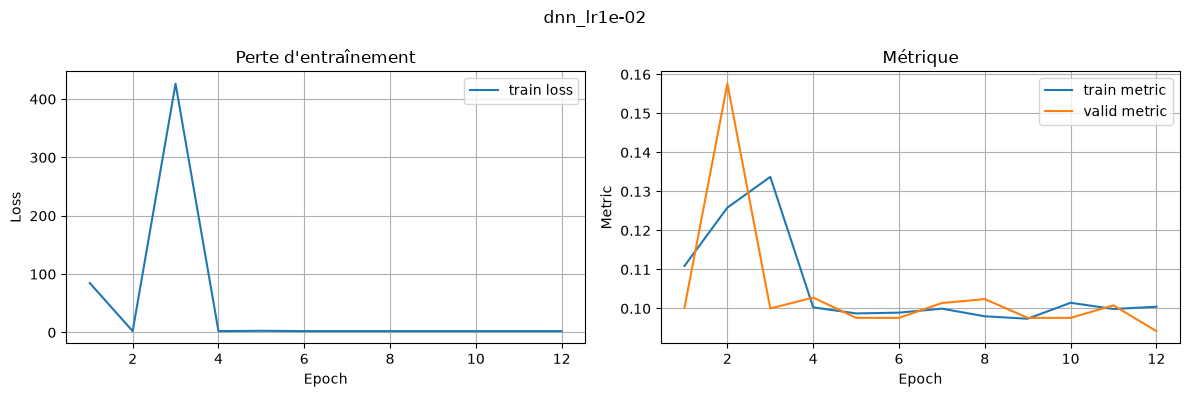

2026-11-04 10:58 | dnn_lr1e-02 | early stopping | epoch 2 | train loss: 2.2753 | train metric: 0.1258 | valid metric: 0.1576


In [ ]:
# Essai 1
lr = 1e-2

model = make_model(n_layers=20, n_hidden=100, device=device)
optimizer = torch.optim.NAdam(model.parameters(), lr=lr)

history = train_with_early_stopping(
    model,
    optimizer,
    criterion,
    metric,
    train_loader,
    valid_loader,
    n_epochs,
    device="mps",
    model_name=f"dnn_lr{lr:.0e}",
)

Epoch 1/100, train loss: 2.1712, train metric: 0.1715, valid metric: 0.2378 (best) in 6.0s
Epoch 2/100, train loss: 1.9177, train metric: 0.2802, valid metric: 0.3036 (best) in 6.0s
Epoch 3/100, train loss: 1.8033, train metric: 0.3350, valid metric: 0.3478 (best) in 6.1s
Epoch 4/100, train loss: 1.7306, train metric: 0.3710, valid metric: 0.3664 (best) in 6.0s
Epoch 5/100, train loss: 1.6663, train metric: 0.3956, valid metric: 0.3758 (best) in 6.2s
Epoch 6/100, train loss: 1.6035, train metric: 0.4166, valid metric: 0.4038 (best) in 6.1s
Epoch 7/100, train loss: 1.5565, train metric: 0.4380, valid metric: 0.4304 (best) in 6.1s
Epoch 8/100, train loss: 1.5265, train metric: 0.4520, valid metric: 0.4302 in 6.2s
Epoch 9/100, train loss: 1.4926, train metric: 0.4635, valid metric: 0.4358 (best) in 6.3s
Epoch 10/100, train loss: 1.4585, train metric: 0.4753, valid metric: 0.4328 in 6.2s
Epoch 11/100, train loss: 1.4285, train metric: 0.4879, valid metric: 0.4472 (best) in 6.3s
Epoch 12/10

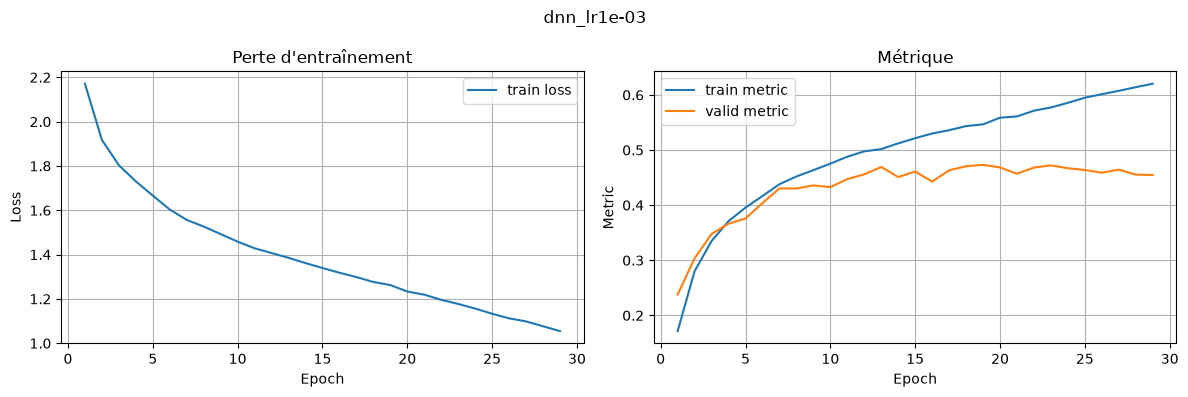

2026-11-14 22:36 | dnn_lr1e-03 | early stopping | epoch 19 | train loss: 1.2626 | train metric: 0.5466 | valid metric: 0.4732


In [9]:
# Essai 2
lr = 1e-3

model = make_model(n_layers=20, n_hidden=100, device=device)
optimizer = torch.optim.NAdam(model.parameters(), lr=lr)

history = train_with_early_stopping(
    model,
    optimizer,
    criterion,
    metric,
    train_loader,
    valid_loader,
    n_epochs,
    device="mps",
    model_name=f"dnn_lr{lr:.0e}",
)

Epoch 1/100, train loss: 2.0782, train metric: 0.2252, valid metric: 0.2664 (best) in 3.4s
Epoch 2/100, train loss: 1.8317, train metric: 0.3251, valid metric: 0.3392 (best) in 3.4s
Epoch 3/100, train loss: 1.7409, train metric: 0.3661, valid metric: 0.3630 (best) in 3.5s
Epoch 4/100, train loss: 1.6841, train metric: 0.3841, valid metric: 0.3746 (best) in 3.4s
Epoch 5/100, train loss: 1.6345, train metric: 0.4070, valid metric: 0.4026 (best) in 3.3s
Epoch 6/100, train loss: 1.5934, train metric: 0.4218, valid metric: 0.4180 (best) in 3.3s
Epoch 7/100, train loss: 1.5538, train metric: 0.4388, valid metric: 0.4304 (best) in 3.3s
Epoch 8/100, train loss: 1.5244, train metric: 0.4506, valid metric: 0.4376 (best) in 3.4s
Epoch 9/100, train loss: 1.4962, train metric: 0.4594, valid metric: 0.4332 in 3.3s
Epoch 10/100, train loss: 1.4725, train metric: 0.4678, valid metric: 0.4412 (best) in 3.3s
Epoch 11/100, train loss: 1.4511, train metric: 0.4786, valid metric: 0.4380 in 3.4s
Epoch 12/10

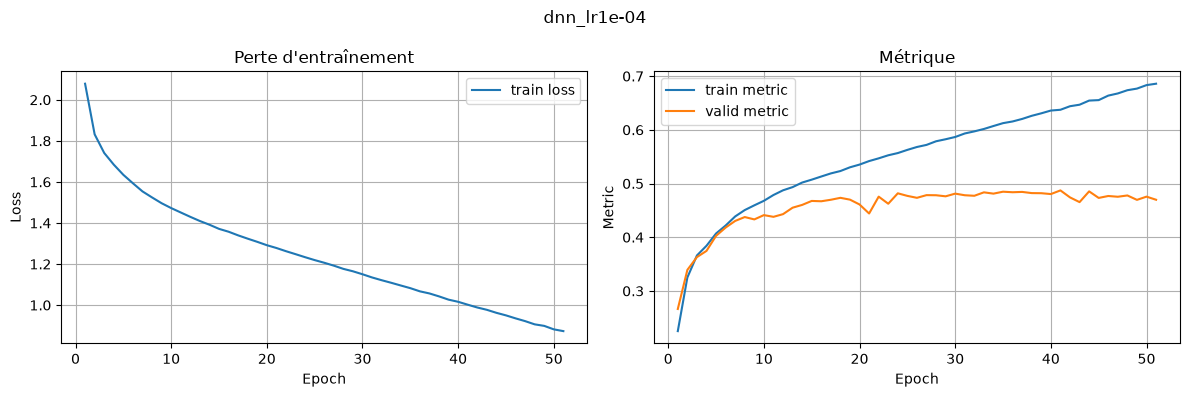

2026-11-04 11:02 | dnn_lr1e-04 | early stopping | epoch 41 | train loss: 1.0020 | train metric: 0.6374 | valid metric: 0.4872


In [ ]:
# Essai 3

lr = 1e-4

model = make_model(n_layers=20, n_hidden=100, device=device)
optimizer = torch.optim.NAdam(model.parameters(), lr=lr)

history = train_with_early_stopping(
    model,
    optimizer,
    criterion,
    metric,
    train_loader,
    valid_loader,
    n_epochs,
    device="mps",
    model_name=f"dnn_lr{lr:.0e}",
)

In [ ]:
# Test de plage de LR

def lr_range_test(
    model, criterion, train_loader, device, lr_min=1e-6, lr_max=1.0, n_steps=300
):
    state = copy.deepcopy(model.state_dict())  # pour restaurer ensuite
    optimizer = torch.optim.NAdam(model.parameters(), lr=lr_min)
    gamma = (lr_max / lr_min) ** (1 / n_steps)
    scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma)

    lrs, losses = [], []
    model.train()
    data_iter = iter(train_loader)
    for _ in range(n_steps):
        try:
            X, y = next(data_iter)
        except StopIteration:
            data_iter = iter(train_loader)
            X, y = next(data_iter)
        X, y = X.to(device), y.to(device)

        optimizer.zero_grad()
        loss = criterion(model(X), y)
        loss.backward()
        optimizer.step()

        lrs.append(optimizer.param_groups[0]["lr"])
        losses.append(loss.item())
        scheduler.step()
        if loss.item() > 4 * min(losses) or not torch.isfinite(loss):  # divergence
            break

    model.load_state_dict(state)  # modèle remis à l'état initial
    plt.plot(lrs, losses)
    plt.xscale("log")
    plt.xlabel("learning rate")
    plt.ylabel("loss")
    plt.grid(True)
    plt.show()

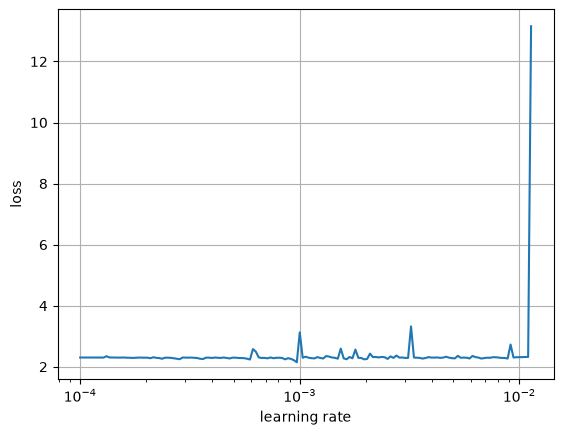

In [29]:
model = make_model(device=device)
lr_range_test(model, criterion, train_loader, lr_min=1e-4, lr_max=1, device="mps")

c) Now try adding batch-norm

In [ ]:
class DNN_BN_CIFAR10(nn.Module):
    def __init__(self, in_features, n_layers, n_hidden, n_classes):
        super().__init__()
        layers = [nn.Flatten()]

        for _ in range(n_layers - 1):
            layers.append(nn.BatchNorm1d(in_features))
            layers.append(nn.Linear(in_features, n_hidden))
            layers.append(nn.SiLU())
            in_features = n_hidden

        layers.append(nn.Linear(n_hidden, n_classes))
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)

def make_model_withBN(n_layers=20, n_hidden=100, device="cpu"):
    torch.manual_seed(42)
    model = DNN_BN_CIFAR10(
        in_features=32 * 32 * 3,
        n_layers=n_layers,
        n_hidden=n_hidden,
        n_classes=10,
    )
    model.apply(use_he_init)
    return model.to(device)

Epoch 1/100, train loss: 2.1250, train metric: 0.2317, valid metric: 0.3352 (best) in 5.5s
Epoch 2/100, train loss: 1.7823, train metric: 0.3539, valid metric: 0.3772 (best) in 5.9s
Epoch 3/100, train loss: 1.6520, train metric: 0.4055, valid metric: 0.4236 (best) in 5.9s
Epoch 4/100, train loss: 1.5629, train metric: 0.4439, valid metric: 0.4354 (best) in 5.6s
Epoch 5/100, train loss: 1.4966, train metric: 0.4693, valid metric: 0.4646 (best) in 5.5s
Epoch 6/100, train loss: 1.4396, train metric: 0.4876, valid metric: 0.4712 (best) in 5.4s
Epoch 7/100, train loss: 1.3908, train metric: 0.5055, valid metric: 0.4808 (best) in 5.4s
Epoch 8/100, train loss: 1.3482, train metric: 0.5206, valid metric: 0.4876 (best) in 5.4s
Epoch 9/100, train loss: 1.3116, train metric: 0.5364, valid metric: 0.5002 (best) in 5.9s
Epoch 10/100, train loss: 1.2718, train metric: 0.5500, valid metric: 0.5014 (best) in 6.0s
Epoch 11/100, train loss: 1.2384, train metric: 0.5618, valid metric: 0.4926 in 5.5s
Epoc

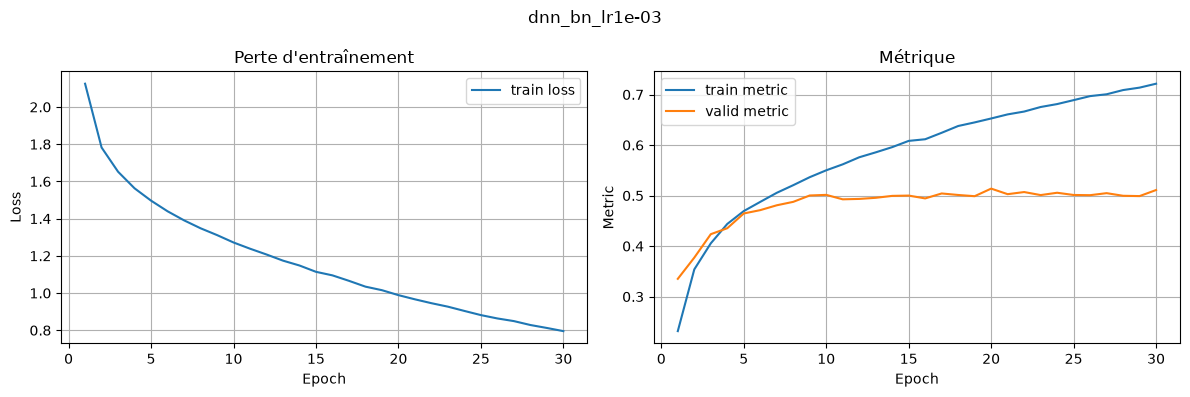

2026-11-04 11:08 | dnn_bn_lr1e-03 | early stopping | epoch 20 | train loss: 0.9888 | train metric: 0.6526 | valid metric: 0.5138


In [ ]:
# Essai 1
lr = 1e-3

model = make_model_withBN(n_layers=20, n_hidden=100, device=device)
optimizer = torch.optim.NAdam(model.parameters(), lr=lr)

history = train_with_early_stopping(
    model,
    optimizer,
    criterion,
    metric,
    train_loader,
    valid_loader,
    n_epochs,
    device="mps",
    model_name=f"dnn_bn_lr{lr:.0e}",
)

Epoch 1/100, train loss: 2.5809, train metric: 0.1119, valid metric: 0.1308 (best) in 5.5s
Epoch 2/100, train loss: 2.3715, train metric: 0.1418, valid metric: 0.1722 (best) in 5.6s
Epoch 3/100, train loss: 2.2410, train metric: 0.1793, valid metric: 0.2136 (best) in 5.4s
Epoch 4/100, train loss: 2.1213, train metric: 0.2194, valid metric: 0.2342 (best) in 5.4s
Epoch 5/100, train loss: 2.0183, train metric: 0.2561, valid metric: 0.2676 (best) in 5.5s
Epoch 6/100, train loss: 1.9436, train metric: 0.2843, valid metric: 0.3042 (best) in 5.7s
Epoch 7/100, train loss: 1.8751, train metric: 0.3112, valid metric: 0.3188 (best) in 5.6s
Epoch 8/100, train loss: 1.8215, train metric: 0.3326, valid metric: 0.3474 (best) in 5.5s
Epoch 9/100, train loss: 1.7752, train metric: 0.3513, valid metric: 0.3584 (best) in 5.7s
Epoch 10/100, train loss: 1.7307, train metric: 0.3705, valid metric: 0.3766 (best) in 5.6s
Epoch 11/100, train loss: 1.6914, train metric: 0.3874, valid metric: 0.3798 (best) in 6.

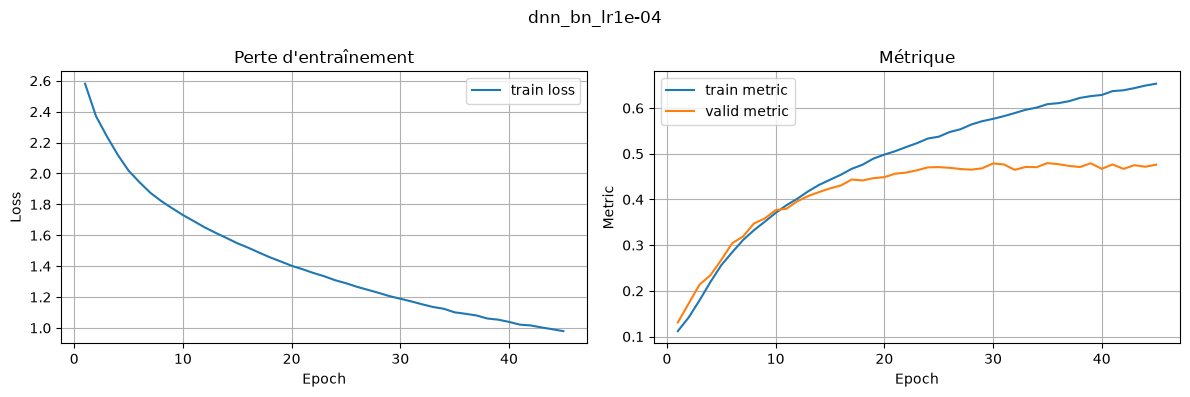

2026-11-04 11:12 | dnn_bn_lr1e-04 | early stopping | epoch 35 | train loss: 1.1009 | train metric: 0.6085 | valid metric: 0.4796


In [ ]:
# Essai 2
lr = 1e-4

model = make_model_withBN(n_layers=20, n_hidden=100, device=device)
optimizer = torch.optim.NAdam(model.parameters(), lr=lr)

history = train_with_early_stopping(
    model,
    optimizer,
    criterion,
    metric,
    train_loader,
    valid_loader,
    n_epochs,
    device="mps",
    model_name=f"dnn_bn_lr{lr:.0e}",
)

d) Try replacing BN With SELU. Adjust the network to ensure self-normalization

In [ ]:
# Inputs standardization calculation
class Standardize(nn.Module):
    def __init__(self, sample):
        super().__init__()
        flat = torch.flatten(sample, start_dim=1)
        mean = flat.mean(dim=0, keepdim=True)
        std = flat.std(dim=0, keepdim=True)
        self.register_buffer("mean", mean)
        self.register_buffer("std", std)

    def forward(self, x):
        return (x - self.mean) / self.std


all_images = torch.stack([img for img, _ in train_data])
standardize = Standardize(all_images)

In [ ]:
# Model architecture with SELU
class DNN_SELU_CIFAR10(nn.Module):
    def __init__(self, in_features, n_layers, n_hidden, n_classes):
        super().__init__()
        layers = [nn.Flatten(), standardize]

        for _ in range(n_layers - 1):
            layers.append(nn.Linear(in_features, n_hidden))
            layers.append(nn.SELU())
            in_features = n_hidden

        layers.append(nn.Linear(n_hidden, n_classes))
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)


# LeCun normal initialization
def use_lecun_init(module):
    if isinstance(module, nn.Linear):
        nn.init.kaiming_normal_(module.weight, mode="fan_in", nonlinearity="linear")
        nn.init.zeros_(module.bias)


# New model instanciation
def make_model_SELU(n_layers=20, n_hidden=100, device="cpu"):
    torch.manual_seed(42)
    model = DNN_SELU_CIFAR10(
        in_features=32 * 32 * 3,
        n_layers=n_layers,
        n_hidden=n_hidden,
        n_classes=10,
    )
    model.apply(use_lecun_init)
    return model.to(device)

Epoch 1/100, train loss: 1.8550, train metric: 0.3349, valid metric: 0.3592 (best) in 3.7s
Epoch 2/100, train loss: 1.6405, train metric: 0.4143, valid metric: 0.4094 (best) in 3.4s
Epoch 3/100, train loss: 1.5402, train metric: 0.4526, valid metric: 0.4348 (best) in 3.3s
Epoch 4/100, train loss: 1.4634, train metric: 0.4827, valid metric: 0.4504 (best) in 3.4s
Epoch 5/100, train loss: 1.4007, train metric: 0.5051, valid metric: 0.4686 (best) in 3.5s
Epoch 6/100, train loss: 1.3494, train metric: 0.5258, valid metric: 0.4534 in 3.5s
Epoch 7/100, train loss: 1.3029, train metric: 0.5428, valid metric: 0.4712 (best) in 3.4s
Epoch 8/100, train loss: 1.2630, train metric: 0.5584, valid metric: 0.4872 (best) in 3.4s
Epoch 9/100, train loss: 1.2250, train metric: 0.5734, valid metric: 0.4872 in 3.4s
Epoch 10/100, train loss: 1.1856, train metric: 0.5879, valid metric: 0.4850 in 3.4s
Epoch 11/100, train loss: 1.1546, train metric: 0.5982, valid metric: 0.5040 (best) in 3.4s
Epoch 12/100, trai

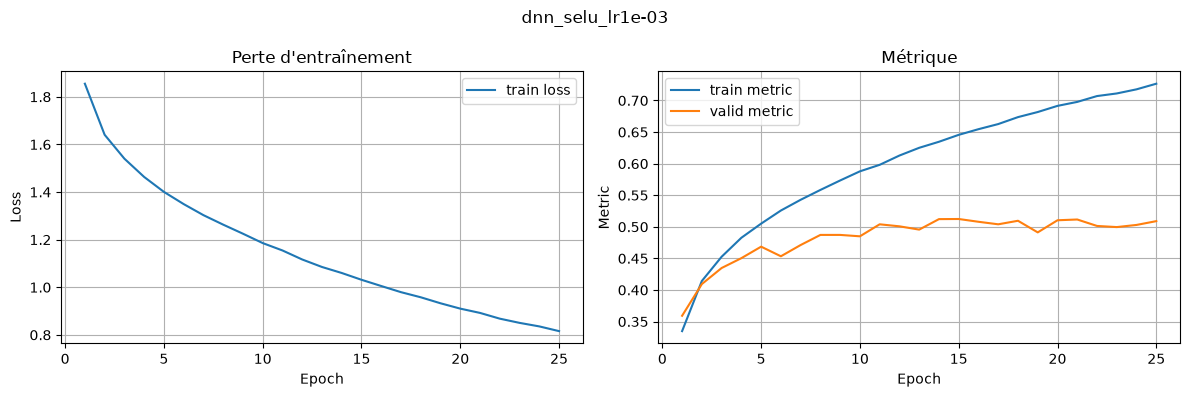

2026-11-05 10:04 | dnn_selu_lr1e-03 | early stopping | epoch 15 | train loss: 1.0314 | train metric: 0.6456 | valid metric: 0.5124


In [ ]:
lr = 1e-3

model = make_model_SELU(n_layers=20, n_hidden=100, device=device)
optimizer = torch.optim.NAdam(model.parameters(), lr=lr)

history = train_with_early_stopping(
    model,
    optimizer,
    criterion,
    metric,
    train_loader,
    valid_loader,
    n_epochs,
    device="mps",
    model_name=f"dnn_selu_lr{lr:.0e}",
)

Epoch 1/100, train loss: 1.8429, train metric: 0.3367, valid metric: 0.3882 (best) in 3.5s
Epoch 2/100, train loss: 1.6155, train metric: 0.4203, valid metric: 0.4398 (best) in 3.5s
Epoch 3/100, train loss: 1.5125, train metric: 0.4614, valid metric: 0.4448 (best) in 3.5s
Epoch 4/100, train loss: 1.4418, train metric: 0.4862, valid metric: 0.4554 (best) in 3.6s
Epoch 5/100, train loss: 1.3807, train metric: 0.5095, valid metric: 0.4632 (best) in 3.5s
Epoch 6/100, train loss: 1.3272, train metric: 0.5288, valid metric: 0.4702 (best) in 3.4s
Epoch 7/100, train loss: 1.2826, train metric: 0.5432, valid metric: 0.4812 (best) in 3.4s
Epoch 8/100, train loss: 1.2381, train metric: 0.5612, valid metric: 0.4762 in 3.4s
Epoch 9/100, train loss: 1.1990, train metric: 0.5738, valid metric: 0.4688 in 3.3s
Epoch 10/100, train loss: 1.1609, train metric: 0.5903, valid metric: 0.4710 in 3.3s
Epoch 11/100, train loss: 1.1242, train metric: 0.6035, valid metric: 0.4750 in 3.4s
Epoch 12/100, train loss:

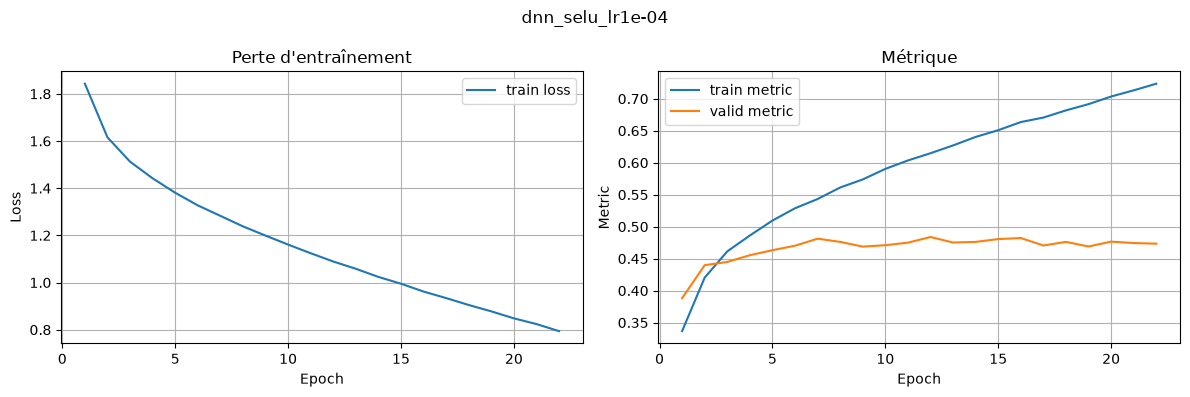

2026-11-05 10:05 | dnn_selu_lr1e-04 | early stopping | epoch 12 | train loss: 1.0892 | train metric: 0.6148 | valid metric: 0.4838


In [ ]:
lr = 1e-4

model = make_model_SELU(n_layers=20, n_hidden=100, device=device)
optimizer = torch.optim.NAdam(model.parameters(), lr=lr)

history = train_with_early_stopping(
    model,
    optimizer,
    criterion,
    metric,
    train_loader,
    valid_loader,
    n_epochs,
    device="mps",
    model_name=f"dnn_selu_lr{lr:.0e}",
)

f) Try regularizing the model with alpha dropout. Withour retraining it, see if you can achieve better accuracy with MC dropout.

In [ ]:
# Model architecture with AlphaDropout
class DNN_DROPOUT_CIFAR10(nn.Module):
    def __init__(self, in_features, n_layers, n_hidden, n_classes, dropout):
        super().__init__()
        layers = [nn.Flatten(), standardize]

        for _ in range(n_layers - 1):
            layers.append(nn.Linear(in_features, n_hidden))
            layers.append(nn.SELU())
            layers.append(nn.AlphaDropout(p=dropout))
            in_features = n_hidden

        layers.append(nn.Linear(n_hidden, n_classes))
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)


# New model instanciation
def make_model_DROPOUT(n_layers=20, n_hidden=100, device="cpu", dropout=0.1):
    torch.manual_seed(42)
    model = DNN_DROPOUT_CIFAR10(
        in_features=32 * 32 * 3,
        n_layers=n_layers,
        n_hidden=n_hidden,
        n_classes=10,
        dropout=dropout,
    )
    model.apply(use_lecun_init)
    return model.to(device)

Epoch 1/100, train loss: 2.1429, train metric: 0.1999, valid metric: 0.2484 (best) in 3.7s
Epoch 2/100, train loss: 1.9546, train metric: 0.2498, valid metric: 0.2842 (best) in 3.8s
Epoch 3/100, train loss: 1.8589, train metric: 0.2978, valid metric: 0.3150 (best) in 3.7s
Epoch 4/100, train loss: 1.7960, train metric: 0.3354, valid metric: 0.3474 (best) in 3.5s
Epoch 5/100, train loss: 1.7419, train metric: 0.3598, valid metric: 0.3666 (best) in 3.6s
Epoch 6/100, train loss: 1.7104, train metric: 0.3722, valid metric: 0.3924 (best) in 3.6s
Epoch 7/100, train loss: 1.6794, train metric: 0.3847, valid metric: 0.3932 (best) in 3.6s
Epoch 8/100, train loss: 1.6515, train metric: 0.3962, valid metric: 0.4028 (best) in 3.5s
Epoch 9/100, train loss: 1.6159, train metric: 0.4094, valid metric: 0.4080 (best) in 3.6s
Epoch 10/100, train loss: 1.5996, train metric: 0.4163, valid metric: 0.4112 (best) in 3.5s
Epoch 11/100, train loss: 1.5806, train metric: 0.4254, valid metric: 0.4108 in 3.6s
Epoc

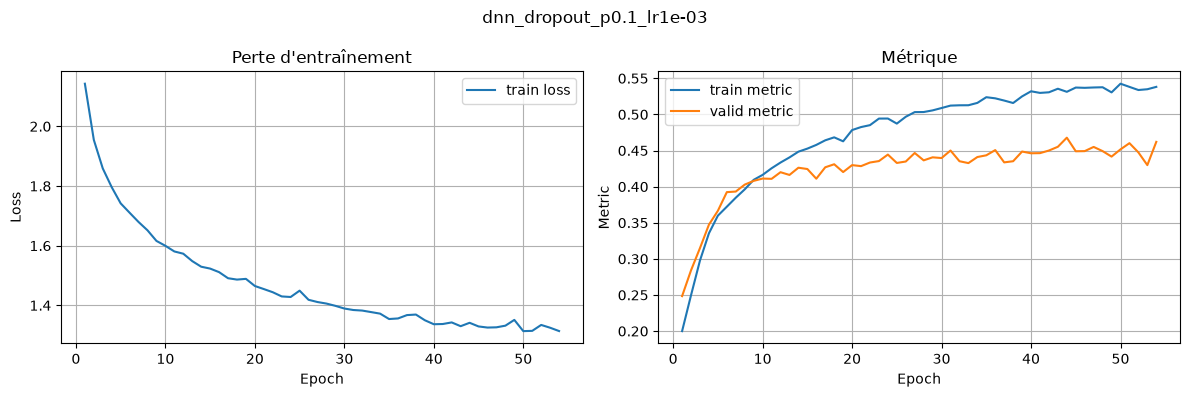

2026-11-05 10:18 | dnn_dropout_p0.1_lr1e-03 | early stopping | epoch 44 | train loss: 1.3415 | train metric: 0.5313 | valid metric: 0.4678


In [ ]:
lr = 1e-3
dropout = 0.1

model = make_model_DROPOUT(n_layers=20, n_hidden=100, device=device, dropout=dropout)
optimizer = torch.optim.NAdam(model.parameters(), lr=lr)

history = train_with_early_stopping(
    model,
    optimizer,
    criterion,
    metric,
    train_loader,
    valid_loader,
    n_epochs,
    device="mps",
    model_name=f"dnn_dropout_p{dropout}_lr{lr:.0e}",
)

Epoch 1/100, train loss: 2.4727, train metric: 0.0982, valid metric: 0.1074 (best) in 3.6s
Epoch 2/100, train loss: 2.3281, train metric: 0.1007, valid metric: 0.0844 in 3.6s
Epoch 3/100, train loss: 2.3112, train metric: 0.0996, valid metric: 0.1322 (best) in 3.5s
Epoch 4/100, train loss: 2.3081, train metric: 0.0985, valid metric: 0.1042 in 3.6s
Epoch 5/100, train loss: 2.3078, train metric: 0.1010, valid metric: 0.1068 in 3.6s
Epoch 6/100, train loss: 2.3076, train metric: 0.0996, valid metric: 0.0816 in 3.6s
Epoch 7/100, train loss: 2.3061, train metric: 0.1013, valid metric: 0.0904 in 3.5s
Epoch 8/100, train loss: 2.3072, train metric: 0.0979, valid metric: 0.1008 in 3.8s
Epoch 9/100, train loss: 2.3061, train metric: 0.1014, valid metric: 0.0936 in 3.7s
Epoch 10/100, train loss: 2.2352, train metric: 0.1358, valid metric: 0.1646 (best) in 3.7s
Epoch 11/100, train loss: 2.1647, train metric: 0.1598, valid metric: 0.1772 (best) in 3.6s
Epoch 12/100, train loss: 2.1454, train metric

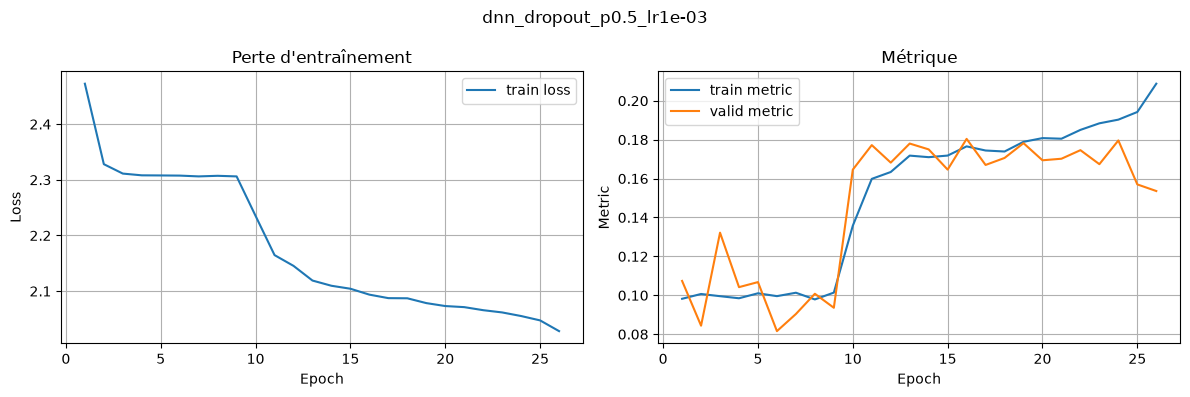

2026-11-05 10:19 | dnn_dropout_p0.5_lr1e-03 | early stopping | epoch 16 | train loss: 2.0937 | train metric: 0.1766 | valid metric: 0.1804


In [ ]:
lr = 1e-3
dropout = 0.5

model = make_model_DROPOUT(n_layers=20, n_hidden=100, device=device, dropout=dropout)
optimizer = torch.optim.NAdam(model.parameters(), lr=lr)

history = train_with_early_stopping(
    model,
    optimizer,
    criterion,
    metric,
    train_loader,
    valid_loader,
    n_epochs,
    device="mps",
    model_name=f"dnn_dropout_p{dropout}_lr{lr:.0e}",
)

Epoch 1/100, train loss: 2.2575, train metric: 0.1888, valid metric: 0.2678 (best) in 3.5s
Epoch 2/100, train loss: 2.0454, train metric: 0.2462, valid metric: 0.3344 (best) in 3.5s
Epoch 3/100, train loss: 1.9426, train metric: 0.2885, valid metric: 0.3664 (best) in 3.5s
Epoch 4/100, train loss: 1.8673, train metric: 0.3208, valid metric: 0.3948 (best) in 3.5s
Epoch 5/100, train loss: 1.8096, train metric: 0.3454, valid metric: 0.4112 (best) in 3.6s
Epoch 6/100, train loss: 1.7676, train metric: 0.3600, valid metric: 0.4142 (best) in 3.5s
Epoch 7/100, train loss: 1.7349, train metric: 0.3782, valid metric: 0.4358 (best) in 3.5s
Epoch 8/100, train loss: 1.6934, train metric: 0.3953, valid metric: 0.4442 (best) in 3.5s
Epoch 9/100, train loss: 1.6704, train metric: 0.4092, valid metric: 0.4450 (best) in 3.6s
Epoch 10/100, train loss: 1.6437, train metric: 0.4145, valid metric: 0.4592 (best) in 3.5s
Epoch 11/100, train loss: 1.6181, train metric: 0.4260, valid metric: 0.4530 in 3.5s
Epoc

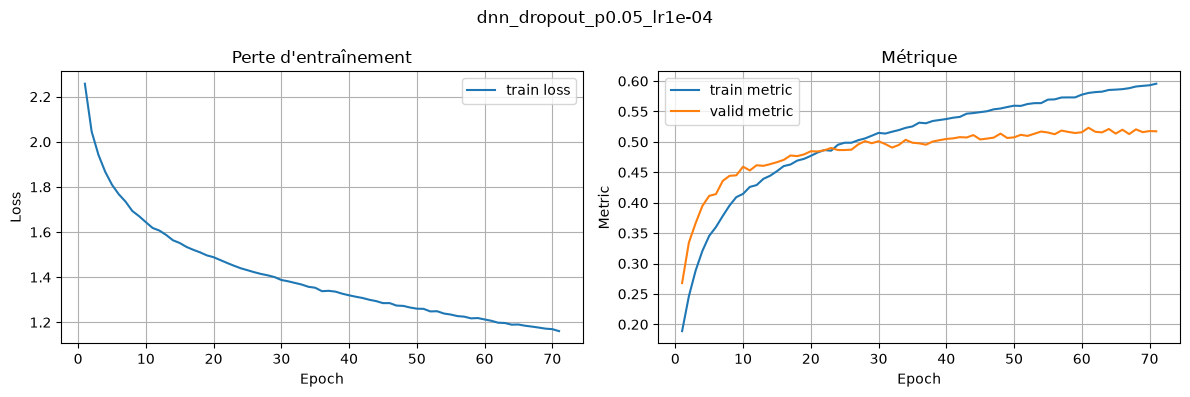

2026-11-05 10:24 | dnn_dropout_p0.05_lr1e-04 | early stopping | epoch 61 | train loss: 1.2066 | train metric: 0.5805 | valid metric: 0.5232


In [ ]:
lr = 1e-4
dropout = 0.05

model = make_model_DROPOUT(n_layers=20, n_hidden=100, device=device, dropout=dropout)
optimizer = torch.optim.NAdam(model.parameters(), lr=lr)

history = train_with_early_stopping(
    model,
    optimizer,
    criterion,
    metric,
    train_loader,
    valid_loader,
    n_epochs,
    device="mps",
    model_name=f"dnn_dropout_p{dropout}_lr{lr:.0e}",
)

In [ ]:
def evaluate_mc(model, data_loader, metric, n_mc=100, device="cpu"):
    model.eval()
    for module in model.modules():
        if isinstance(module, (nn.Dropout, nn.AlphaDropout)):
            module.train()

    metric.reset()
    with torch.no_grad():
        for X, y in data_loader:
            X, y = X.to(device), y.to(device)
            probs = torch.stack([model(X).softmax(dim=1) for _ in range(n_mc)]).mean(
                dim=0
            )
            metric.update(probs, y)

    model.eval()  # remet le dropout en mode évaluation
    return metric.compute().item()

In [ ]:
valid_metric = evaluate(model, valid_loader, metric, device)
print("Validation metric without MC Dropout : ", valid_metric)

n_mc = 100
print(
    f"Validation metric with MC Dropout, n_mc = {n_mc} : ",
    evaluate_mc(model, valid_loader, metric, n_mc, device=device),
)

Validation metric without MC Dropout :  0.5231999754905701
Validation metric with MC Dropout, n_mc = 100 :  0.5242000222206116


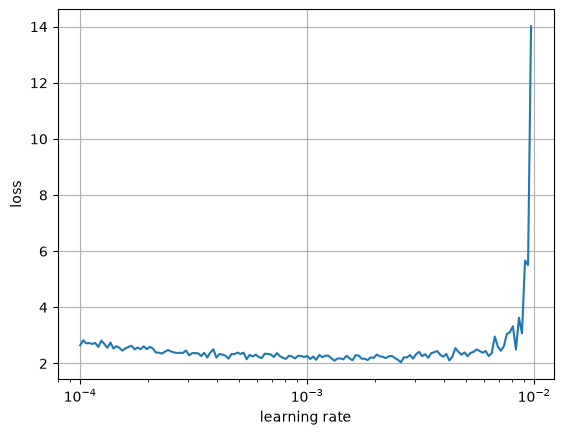

In [ ]:
dropout = 0.05
model = make_model_DROPOUT(n_layers=20, n_hidden=100, device=device, dropout=dropout)
lr_range_test(model, criterion, train_loader, lr_min=1e-4, lr_max=1, device="mps")

g) Retrain the model using 1cycle scheduling.

In [ ]:
# Training function
def train_with_scheduler(
    model,
    optimizer,
    criterion,
    metric,
    train_loader,
    valid_loader,
    n_epochs=10,
    patience=10,
    device="cpu",
    model_dir="models/ch11",
    model_name="model",
    scheduler=None,
):

    model_dir = Path(model_dir)
    model_dir.mkdir(parents=True, exist_ok=True)
    checkpoint_path = model_dir / f"{model_name}.pt"

    history = {"train_losses": [], "train_metrics": [], "valid_metrics": [], "lrs": []}
    best_metric = 0.0
    patience_counter = 0
    stopped_early = False

    for epoch in range(n_epochs):
        total_loss = 0.0
        metric.reset()
        model.train()
        t0 = time.time()

        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            y_pred = model(X_batch)
            loss = criterion(y_pred, y_batch)
            total_loss += loss.item()
            loss.backward()
            optimizer.step()
            if scheduler is not None:
                scheduler.step()
            metric.update(y_pred, y_batch)

        train_metric = metric.compute().item()
        valid_metric = evaluate(model, valid_loader, metric, device)
        if valid_metric > best_metric:
            torch.save(model.state_dict(), checkpoint_path)
            best_metric = valid_metric
            patience_counter = 0
            best = " (best)"
        else:
            patience_counter += 1
            best = ""

        t1 = time.time()
        history["train_losses"].append(total_loss / len(train_loader))
        history["train_metrics"].append(train_metric)
        history["valid_metrics"].append(valid_metric)
        history["lrs"].append(optimizer.param_groups[0]["lr"])
        print(
            f"Epoch {epoch + 1}/{n_epochs}, "
            f"train loss: {history['train_losses'][-1]:.4f}, "
            f"train metric: {history['train_metrics'][-1]:.4f}, "
            f"valid metric: {history['valid_metrics'][-1]:.4f}{best}"
            f" in {t1 - t0:.1f}s"
        )
        if patience_counter >= patience:
            print("Early stopping!")
            stopped_early = True
            break

    # Reload best model
    model.load_state_dict(torch.load(checkpoint_path, map_location=device))

    # Save and plot training curves
    with open(model_dir / f"{model_name}_history.json", "w") as f:
        json.dump(history, f, indent=2)
    plot_learning_curves(
        history,
        save_path=model_dir / f"{model_name}_learning_curves.png",
        title=model_name,
    )

    # Results
    best_epoch = history["valid_metrics"].index(max(history["valid_metrics"]))
    status = "early stopping" if stopped_early else "entraînement complet"
    summary = (
        f"{dt.now():%Y-%m-%d %H:%M} | {model_name} | {status} | "
        f"epoch {best_epoch + 1} | "
        f"train loss: {history['train_losses'][best_epoch]:.4f} | "
        f"train metric: {history['train_metrics'][best_epoch]:.4f} | "
        f"valid metric: {history['valid_metrics'][best_epoch]:.4f}"
    )
    print(summary)
    with open(model_dir / "summary.txt", "a") as f:
        f.write(summary + "\n")

    return history

Epoch 1/30, train loss: 2.2860, train metric: 0.1828, valid metric: 0.2756 (best) in 3.9s
Epoch 2/30, train loss: 2.0504, train metric: 0.2446, valid metric: 0.3384 (best) in 3.6s
Epoch 3/30, train loss: 1.9200, train metric: 0.3022, valid metric: 0.3772 (best) in 3.6s
Epoch 4/30, train loss: 1.8138, train metric: 0.3493, valid metric: 0.4130 (best) in 3.6s
Epoch 5/30, train loss: 1.7363, train metric: 0.3796, valid metric: 0.4226 (best) in 3.6s
Epoch 6/30, train loss: 1.6814, train metric: 0.4003, valid metric: 0.4202 in 3.7s
Epoch 7/30, train loss: 1.6376, train metric: 0.4206, valid metric: 0.4298 (best) in 3.6s
Epoch 8/30, train loss: 1.6061, train metric: 0.4340, valid metric: 0.4352 (best) in 3.6s
Epoch 9/30, train loss: 1.5859, train metric: 0.4449, valid metric: 0.4452 (best) in 3.7s
Epoch 10/30, train loss: 1.5713, train metric: 0.4505, valid metric: 0.4456 (best) in 3.6s
Epoch 11/30, train loss: 1.5602, train metric: 0.4531, valid metric: 0.4378 in 3.7s
Epoch 12/30, train los

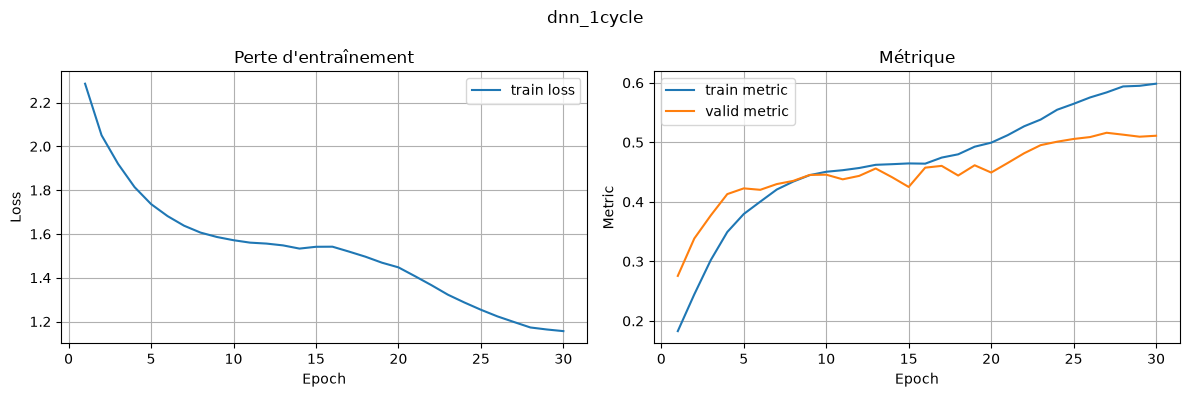

2026-11-06 10:42 | dnn_1cycle | entraînement complet | epoch 27 | train loss: 1.1979 | train metric: 0.5838 | valid metric: 0.5160


In [ ]:
dropout = 0.05
model = make_model_DROPOUT(n_layers=20, n_hidden=100, device=device, dropout=dropout)

n_epochs = 30
optimizer = torch.optim.NAdam(
    model.parameters(), lr=1e-3
)  # ce lr sera écrasé par le scheduler
scheduler = OneCycleLR(
    optimizer,
    max_lr=2e-3,
    epochs=n_epochs,
    steps_per_epoch=len(train_loader),
    pct_start=0.5,  # part du cycle passée à monter
    div_factor=25,  # lr initial = max_lr / 25
    final_div_factor=1e3,  # lr final = lr initial / 1e4
)

history = train_with_scheduler(
    model,
    optimizer,
    criterion,
    metric,
    train_loader,
    valid_loader,
    n_epochs=n_epochs,
    patience=n_epochs,
    device="mps",
    model_name="dnn_1cycle",
    scheduler=scheduler,
)

Epoch 1/60, train loss: 2.2887, train metric: 0.1819, valid metric: 0.2780 (best) in 3.7s
Epoch 2/60, train loss: 2.0703, train metric: 0.2369, valid metric: 0.3294 (best) in 3.7s
Epoch 3/60, train loss: 1.9586, train metric: 0.2837, valid metric: 0.3658 (best) in 3.5s
Epoch 4/60, train loss: 1.8691, train metric: 0.3229, valid metric: 0.3944 (best) in 3.5s
Epoch 5/60, train loss: 1.7994, train metric: 0.3539, valid metric: 0.4168 (best) in 3.6s
Epoch 6/60, train loss: 1.7393, train metric: 0.3760, valid metric: 0.4144 in 3.8s
Epoch 7/60, train loss: 1.6886, train metric: 0.4009, valid metric: 0.4390 (best) in 3.7s
Epoch 8/60, train loss: 1.6429, train metric: 0.4198, valid metric: 0.4404 (best) in 3.6s
Epoch 9/60, train loss: 1.6122, train metric: 0.4314, valid metric: 0.4502 (best) in 3.6s
Epoch 10/60, train loss: 1.5818, train metric: 0.4422, valid metric: 0.4580 (best) in 3.8s
Epoch 11/60, train loss: 1.5505, train metric: 0.4534, valid metric: 0.4662 (best) in 4.0s
Epoch 12/60, tr

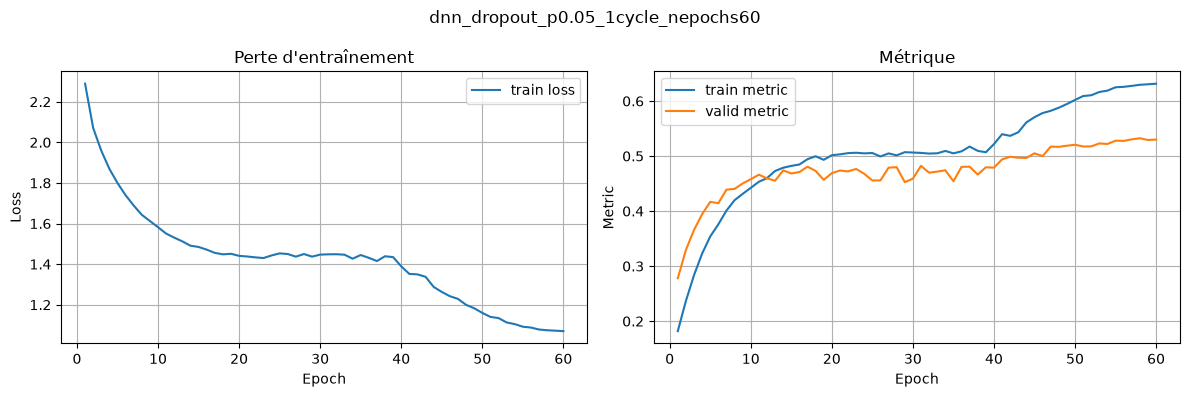

2026-11-06 10:52 | dnn_dropout_p0.05_1cycle_nepochs60 | entraînement complet | epoch 58 | train loss: 1.0743 | train metric: 0.6296 | valid metric: 0.5324


In [ ]:
dropout = 0.05
model = make_model_DROPOUT(n_layers=20, n_hidden=100, device=device, dropout=dropout)

n_epochs = 60
max_lr = 2e-3
optimizer = torch.optim.NAdam(model.parameters(), lr=1e-3)  # ce lr sera écrasé par le scheduler
scheduler = OneCycleLR(
    optimizer,
    max_lr=2e-3,
    epochs=n_epochs,
    steps_per_epoch=len(train_loader),
    pct_start=0.5,  # part du cycle passée à monter
    div_factor=25,  # lr initial = max_lr / 25
    final_div_factor=1e3,  # lr final = lr initial / 1e4
)

history = train_with_scheduler(
    model,
    optimizer,
    criterion,
    metric,
    train_loader,
    valid_loader,
    n_epochs=n_epochs,
    patience=n_epochs,
    device="mps",
    model_name=f"dnn_dropout_p{dropout}_1cycle_nepochs{n_epochs}",
    scheduler=scheduler,
)

EXTRA : Fine-tuning hyperparameters to optimize the model.

In [ ]:
def train_with_pruning(trial, model, optimizer, criterion, metric, train_loader, valid_loader, n_epochs=10, device="cpu", scheduler=None):
    best_metric = 0.0

    for epoch in range(n_epochs):
        model.train()
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            loss = criterion(model(X_batch), y_batch)
            if not math.isfinite(loss.item()):      # divergence : on abandonne l'essai
                raise optuna.TrialPruned()
            loss.backward()
            optimizer.step()
            if scheduler is not None:
                scheduler.step()

        valid_metric = evaluate(model, valid_loader, metric, device)
        best_metric = max(best_metric, valid_metric)

        trial.report(valid_metric, epoch)
        if trial.should_prune():                    # essai nettement moins bon que les autres
            raise optuna.TrialPruned()

    return best_metric

In [48]:
def objective(trial):
    max_lr   = trial.suggest_float("max_lr", 1e-4, 1e-2, log=True)
    n_layers = trial.suggest_int("n_layers", 5, 20)
    n_hidden = trial.suggest_int("n_hidden", 50, 300, step=50)
    dropout  = trial.suggest_float("dropout", 0.0, 0.15, step=0.05)

    model = make_model_DROPOUT(n_layers, n_hidden, device, dropout)
    optimizer = torch.optim.NAdam(model.parameters(), lr=max_lr)
    scheduler = OneCycleLR(
        optimizer, max_lr=max_lr, epochs=n_epochs,
        steps_per_epoch=len(train_loader),
        pct_start=0.5, div_factor=25, final_div_factor=1e3,
    )

    return train_with_pruning(
        trial, model, optimizer, criterion, metric,
        train_loader, valid_loader,
        n_epochs=n_epochs, device=device, scheduler=scheduler,
    )

In [49]:
n_epochs = 15  

torch.manual_seed(42)
criterion = nn.CrossEntropyLoss()
metric = torchmetrics.Accuracy(task="multiclass", num_classes=10).to(device)
sampler = optuna.samplers.TPESampler(seed=42)
pruner = optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=3, interval_steps=1)
study = optuna.create_study(direction="maximize", sampler=sampler, pruner=pruner)
study.optimize(objective, n_trials=30, gc_after_trial=True)

print("Best hyperparameters :", study.best_params)
print("Best validation accuracy  :", study.best_value)

[I 2026-11-06 11:22:28,750] A new study created in memory with name: no-name-43b59820-8a6a-42c3-9a55-c5e4d5577a6e
[I 2026-11-06 11:23:28,891] Trial 0 finished with value: 0.5058000087738037 and parameters: {'max_lr': 0.0005611516415334506, 'n_layers': 20, 'n_hidden': 250, 'dropout': 0.1}. Best is trial 0 with value: 0.5058000087738037.
[I 2026-11-06 11:24:05,335] Trial 1 finished with value: 0.4327999949455261 and parameters: {'max_lr': 0.0002051338263087451, 'n_layers': 7, 'n_hidden': 50, 'dropout': 0.15}. Best is trial 0 with value: 0.5058000087738037.
[I 2026-11-06 11:24:54,149] Trial 2 finished with value: 0.2635999917984009 and parameters: {'max_lr': 0.0015930522616241021, 'n_layers': 16, 'n_hidden': 50, 'dropout': 0.15}. Best is trial 0 with value: 0.5058000087738037.
[I 2026-11-06 11:25:30,628] Trial 3 finished with value: 0.5425999760627747 and parameters: {'max_lr': 0.004622589001020831, 'n_layers': 8, 'n_hidden': 100, 'dropout': 0.0}. Best is trial 3 with value: 0.54259997606

Best hyperparameters : {'max_lr': 0.002470339424391048, 'n_layers': 9, 'n_hidden': 200, 'dropout': 0.05}
Best validation accuracy  : 0.5644000172615051


In [50]:
print(study.trials_dataframe()[["number", "value", "state", "params_max_lr",
                                "params_n_layers", "params_n_hidden", "params_dropout"]]
      .sort_values("value", ascending=False).head(10))

    number   value     state  params_max_lr  params_n_layers  params_n_hidden  \
24      24  0.5644  COMPLETE       0.000932                5              200   
11      11  0.5644  COMPLETE       0.002470                9              200   
9        9  0.5630  COMPLETE       0.000407                6              250   
22      22  0.5568  COMPLETE       0.001124                7              150   
13      13  0.5528  COMPLETE       0.000317                5              250   
5        5  0.5528  COMPLETE       0.001674                7              100   
21      21  0.5482  COMPLETE       0.001629                7              100   
7        7  0.5428  COMPLETE       0.001530                5              200   
3        3  0.5426  COMPLETE       0.004623                8              100   
4        4  0.5360  COMPLETE       0.000406               13              150   

    params_dropout  
24            0.05  
11            0.05  
9             0.05  
22            0.05  
13 

In [51]:
def objective(trial):
    max_lr   = trial.suggest_float("max_lr", 1e-4, 1e-2, log=True)
    n_layers = trial.suggest_int("n_layers", 5, 10)
    n_hidden = trial.suggest_int("n_hidden", 100, 200, step=50)

    model = make_model_DROPOUT(n_layers, n_hidden, device, dropout=0.05)
    optimizer = torch.optim.NAdam(model.parameters(), lr=max_lr)
    scheduler = OneCycleLR(
        optimizer, max_lr=max_lr, epochs=n_epochs,
        steps_per_epoch=len(train_loader),
        pct_start=0.5, div_factor=25, final_div_factor=1e3,
    )

    return train_with_pruning(
        trial, model, optimizer, criterion, metric,
        train_loader, valid_loader,
        n_epochs=n_epochs, device=device, scheduler=scheduler,
    )

In [52]:
n_epochs = 20  

torch.manual_seed(42)
criterion = nn.CrossEntropyLoss()
metric = torchmetrics.Accuracy(task="multiclass", num_classes=10).to(device)
sampler = optuna.samplers.TPESampler(seed=42)
pruner = optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=3, interval_steps=1)
study = optuna.create_study(direction="maximize", sampler=sampler, pruner=pruner)
study.optimize(objective, n_trials=15, gc_after_trial=True)

print("Best hyperparameters :", study.best_params)
print("Best validation accuracy  :", study.best_value)

[I 2026-11-06 11:41:02,255] A new study created in memory with name: no-name-07b758e5-cdcf-48eb-8b0b-c89d83a91c50
[I 2026-11-06 11:41:58,205] Trial 0 finished with value: 0.5544000267982483 and parameters: {'max_lr': 0.0005611516415334506, 'n_layers': 10, 'n_hidden': 200}. Best is trial 0 with value: 0.5544000267982483.
[I 2026-11-06 11:42:41,952] Trial 1 finished with value: 0.5472000241279602 and parameters: {'max_lr': 0.0015751320499779737, 'n_layers': 5, 'n_hidden': 100}. Best is trial 0 with value: 0.5544000267982483.
[I 2026-11-06 11:43:37,253] Trial 2 finished with value: 0.5091999769210815 and parameters: {'max_lr': 0.00013066739238053285, 'n_layers': 10, 'n_hidden': 150}. Best is trial 0 with value: 0.5544000267982483.
[I 2026-11-06 11:44:23,201] Trial 3 finished with value: 0.5547999739646912 and parameters: {'max_lr': 0.0026070247583707684, 'n_layers': 5, 'n_hidden': 200}. Best is trial 3 with value: 0.5547999739646912.
[I 2026-11-06 11:45:09,418] Trial 4 finished with value

Best hyperparameters : {'max_lr': 0.0026070247583707684, 'n_layers': 5, 'n_hidden': 200}
Best validation accuracy  : 0.5547999739646912


In [54]:
print(study.trials_dataframe()[["number", "value", "state", "params_max_lr",
                                "params_n_layers", "params_n_hidden"]]
      .sort_values("value", ascending=False).head(10))

    number   value     state  params_max_lr  params_n_layers  params_n_hidden
3        3  0.5548  COMPLETE       0.002607                5              200
0        0  0.5544  COMPLETE       0.000561               10              200
1        1  0.5472  COMPLETE       0.001575                5              100
4        4  0.5398  COMPLETE       0.004623                6              100
2        2  0.5092  COMPLETE       0.000131               10              150
6        6  0.4610    PRUNED       0.000731                6              150
14      14  0.4608    PRUNED       0.000448                5              200
11      11  0.4554    PRUNED       0.003040               10              200
12      12  0.4550    PRUNED       0.000331                8              200
8        8  0.4490    PRUNED       0.000817                9              100


Epoch 1/60, train loss: 1.9498, train metric: 0.3164, valid metric: 0.4192 (best) in 2.4s
Epoch 2/60, train loss: 1.7284, train metric: 0.3868, valid metric: 0.4414 (best) in 2.3s
Epoch 3/60, train loss: 1.6365, train metric: 0.4188, valid metric: 0.4646 (best) in 2.3s
Epoch 4/60, train loss: 1.5653, train metric: 0.4432, valid metric: 0.4832 (best) in 2.3s
Epoch 5/60, train loss: 1.5069, train metric: 0.4659, valid metric: 0.4966 (best) in 2.4s
Epoch 6/60, train loss: 1.4452, train metric: 0.4852, valid metric: 0.5078 (best) in 2.3s
Epoch 7/60, train loss: 1.3960, train metric: 0.5040, valid metric: 0.5108 (best) in 2.3s
Epoch 8/60, train loss: 1.3467, train metric: 0.5224, valid metric: 0.5048 in 2.3s
Epoch 9/60, train loss: 1.3060, train metric: 0.5352, valid metric: 0.5174 (best) in 2.3s
Epoch 10/60, train loss: 1.2677, train metric: 0.5474, valid metric: 0.5224 (best) in 2.4s
Epoch 11/60, train loss: 1.2341, train metric: 0.5572, valid metric: 0.5312 (best) in 2.4s
Epoch 12/60, tr

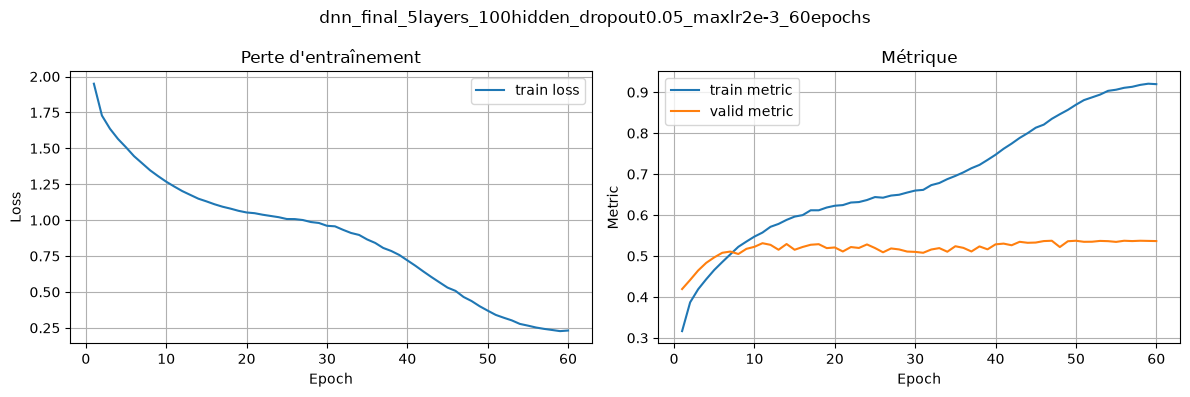

2026-11-06 11:53 | dnn_final_5layers_100hidden_dropout0.05_maxlr2e-3_60epochs | entraînement complet | epoch 47 | train loss: 0.4650 | train metric: 0.8350 | valid metric: 0.5372


In [55]:
dropout = 0.05
model = make_model_DROPOUT(n_layers=5, n_hidden=200, device=device, dropout=dropout)

n_epochs = 60
max_lr = 2e-3
optimizer = torch.optim.NAdam(model.parameters(), lr=max_lr)  # ce lr sera écrasé par le scheduler
scheduler = OneCycleLR(
    optimizer,
    max_lr=max_lr,
    epochs=n_epochs,
    steps_per_epoch=len(train_loader),
    pct_start=0.5,  # part du cycle passée à monter
    div_factor=25,  # lr initial = max_lr / 25
    final_div_factor=1e3,  # lr final = lr initial / 1e4
)

history = train_with_scheduler(
    model,
    optimizer,
    criterion,
    metric,
    train_loader,
    valid_loader,
    n_epochs=n_epochs,
    patience=n_epochs,
    device="mps",
    model_name="dnn_final_5layers_100hidden_dropout0.05_maxlr2e-3_60epochs",
    scheduler=scheduler,
)

In [56]:
test_metric = evaluate(model, test_loader, metric, device)
print(f"Test accuracy : {test_metric:.4f}")

Test accuracy : 0.5401
